# K-Nearest Neighbors and Decision Trees for Regression

Before we implement models using scikit-learn, let's think conceptually about the $k$-nearest neighbors and decision tree algorithms for regression.

In [1]:
import pandas as pd

import numpy as np

import matplotlib.pyplot as plt
from pathlib import Path


## Visualizing K-Nearest Neighbors Regression Functions

A predictive model is simply a function $f$ that maps feature values ${\bf x}$ to target values $y$. We can visualize $f$ when ${\bf x}$ consists of just a single feature. We have seen that a linear regression function $f$ based on a single feature $x$ is a linear function of $x$. What does $f$ look like when the model is a $k$-nearest neighbors regressor?


### K-Nearest Neighbors Regression Functions for a Single Quantitative Feature: Wine Data


Recall the wines data set where our target is log(price), a proxy for quality.
We'll use a K-Nearest Neighbors model for predicting log(price) from a single feature, age.

First, we extract the training data. There is no need to scale the features in this case because there is only one feature. (The point of scaling is to bring all of the *feature* variables to the same scale before computing distances between observations.)

In [2]:
bordeaux_df = pd.read_csv(
    Path("data/bordeaux.csv") if Path("data/bordeaux.csv").exists()
    else "https://dlsun.github.io/pods/data/bordeaux.csv",
                          index_col="year")

# Split the data into training and test sets
bordeaux_train = bordeaux_df.loc[:1980].copy()
bordeaux_test = bordeaux_df.loc[1981:].copy()

# Log transform the target
bordeaux_train["log(price)"] = np.log(bordeaux_train["price"])

# train on a single feature, age
X_train = bordeaux_train[["age"]]
y_train = bordeaux_train["log(price)"]

In [3]:
bordeaux_train[["age", "log(price)"]].sort_values("age").head(5)

,age,log(price)
year,,
1980,12,2.639057
1979,13,3.044522
1978,14,3.295837
1977,15,2.397895
1976,16,3.218876


Let's make a scatterplot of the training data. Careful! In the reading, we made several scatterplots where both the x-axis and y-axis corresponded to *feature* variables (and the target corresponded to color). But now the x-axis is the feature and the y-axis is the target.

<Axes: xlabel='age', ylabel='log(price)'>

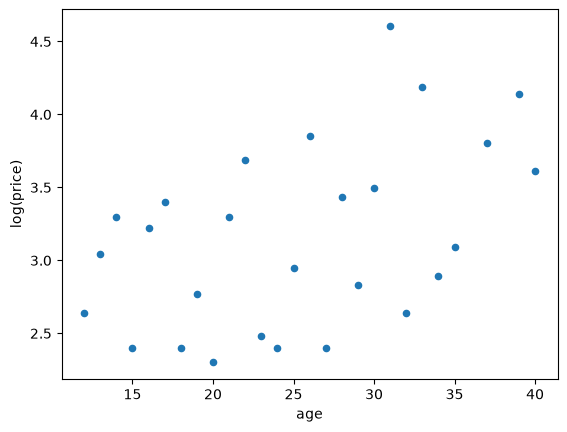

In [4]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

1. Consider a **1-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 13? age = 11.5? age = 12.49? age = 12.51? age = 13.49? age = 13.51?

**Sketch on paper and discuss with your partner.**

2. Consider a **2-nearest neighbor** regression model. Say we want to add the regression function to the scatterplot. Sketch a plot of what the regression function would look like. **Discuss with your partner before proceeding.** Hint: The smallest ages in the training data are 12, 13, 14, etc. What would the predicted price be for age = 12? age = 12.99? age = 13.01? age = 13.99? age = 14.01?

**Sketch on paper and discuss with your partner.**

3. What would the 27-nearest neighbors regression function look like? **Discuss with your partner before proceeding.** Hint: what is special about 27 in this example?

**Sketch on paper and discuss with your partner.**

4. Now we'll fit a K-nearest neighbors regression model and plot the regression function for K=1, 2, 10, 27. The code below basically implements the code from the previous part for each of the values of K. Run the code and **discuss the output with your partner**. Do the regression functions look like what you expected? What happens as K increases?

<Axes: xlabel='age', ylabel='log(price)'>

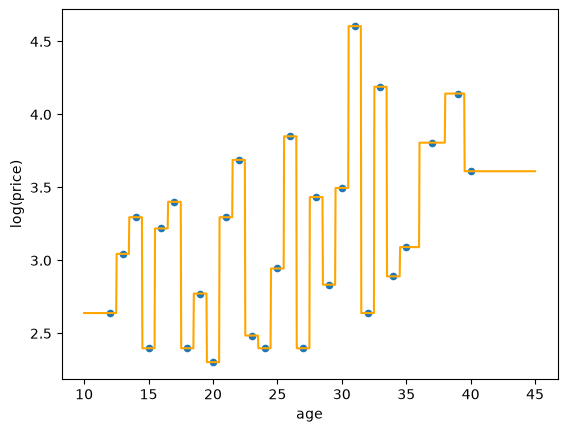

In [5]:
# 1-nearest neighbor model
from sklearn.neighbors import KNeighborsRegressor

# Fit k-nearest neighbors
model = KNeighborsRegressor(n_neighbors=1)
model.fit(X=X_train, y=y_train)

# Define a grid of feature values to make predictions for
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

# Make predictions at those feature values.
y_new_ = pd.Series(
    # ADD YOUR CODE HERE,
    model.predict(X_new),
    index=X_new["age"]
)

# Plot the scatter plot and the predictions (regression function)
bordeaux_train.plot.scatter(x="age", y="log(price)")
y_new_.plot.line(color = "orange")


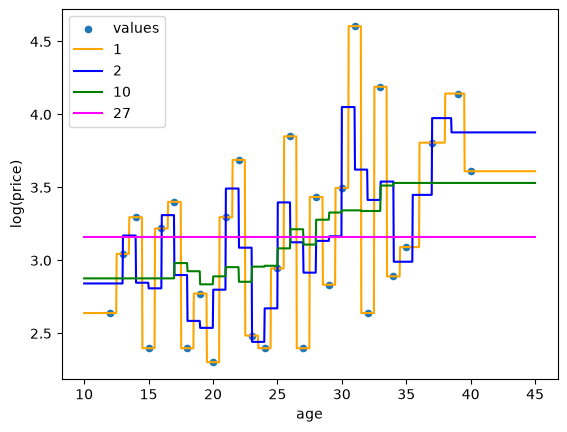

In [6]:
# k-nearest neighbors for several values of k
ks = [1, 2, 10, 27]
colors = ["orange", "blue", "green", "magenta", "black"]

bordeaux_train.plot.scatter(x="age", y="log(price)")

# Define a grid of feature values.
X_new = pd.DataFrame()
X_new["age"] = np.linspace(10, 45, num=1000)

for i in range(len(ks)):

  # Fit k-nearest neighbors
  model = KNeighborsRegressor(n_neighbors=ks[i])
  model.fit(X=X_train, y=y_train)

  # Make predictions at those feature values.
  y_new_ = pd.Series(
      model.predict(X_new),
      index=X_new["age"]
  )

  # Plot the predictions.
  y_new_.plot.line(color = colors[i])
  plt.legend(["values"] + ks);


### K-Nearest Neighbors Regression Functions for a Single Categorical Feature: Housing Data

Recall the Ames housing data set. We'll use a single categorical feature---Neighborhood---to predict SalePrice.

In [7]:
df_ames = pd.read_csv(
    Path("data/AmesHousing.txt") if Path("data/AmesHousing.txt").exists()
    else "https://dlsun.github.io/pods/data/AmesHousing.txt",
    sep="\t"
)

df_ames[["Neighborhood", "SalePrice"]]

,Neighborhood,SalePrice
0,NAmes,215000
1,NAmes,105000
2,NAmes,172000
3,NAmes,244000
4,Gilbert,189900
...,...,...
2925,Mitchel,142500
2926,Mitchel,131000
2927,Mitchel,132000
2928,Mitchel,170000


We'll fit a **10-nearest neighbors** regression model to predict house price using **Neighborhood** as the only feature. Since Neighborhood is categorical we first need to convert it to dummies, using a `ColumnTransformer` and a `Pipeline`.

In [8]:
from sklearn.compose import ColumnTransformer
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

X = df_ames[["Neighborhood"]]
y = df_ames["SalePrice"]

ct = ColumnTransformer(
    [("dummify", OneHotEncoder(), ["Neighborhood"])]
)

knn_model = Pipeline([
    ("preprocessing", ct),
    ("knn", KNeighborsRegressor(n_neighbors=10))
])

knn_model.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessing', ...), ('knn', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Neighborhood']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('dummify', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,ex

Now we'll find the predicted price for each Neighborhood.

In [9]:
neighborhoods = pd.Series(df_ames["Neighborhood"].unique(), name="Neighborhood").to_frame()
neighborhoods["predicted"] = knn_model.predict(neighborhoods)
neighborhoods

,Neighborhood,predicted
0,NAmes,142771.0
1,Gilbert,221722.5
2,StoneBr,300637.0
3,NWAmes,180795.0
4,Somerst,230960.0
5,BrDale,108850.0
6,NPkVill,140115.0
7,NridgHt,346588.3
8,Blmngtn,209917.9
9,NoRidge,325105.0


Let's compare the predicted prices to the mean price for each neighborhood.

In [10]:
pd.merge(pd.merge(neighborhoods,
                  df_ames.groupby("Neighborhood")["SalePrice"].mean(), left_on = "Neighborhood", right_index = True),
         df_ames["Neighborhood"].value_counts(), left_on = "Neighborhood", right_index = True).sort_values("count")

,Neighborhood,predicted,SalePrice,count
27,Landmrk,122920.0,137000.000000,1
26,GrnHill,150790.0,280000.000000,2
12,Greens,181175.0,193531.250000,8
21,Blueste,143590.0,143590.000000,10
6,NPkVill,140115.0,140710.869565,23
25,Veenker,254750.0,248314.583333,24
8,Blmngtn,209917.9,196661.678571,28
5,BrDale,108850.0,105608.333333,30
24,MeadowV,104390.0,95756.486486,37
16,ClearCr,222100.0,208662.090909,44


 5. For what neighborhood is the predicted price equal to the neighborhood's mean price? Why? What is special about that neighborhood? Can you explain why the predicted prices don't match the mean price for the other neighborhoods?

**Discuss with your partner.**

### K-Nearest Neighbors Regression Functions for Two Quantitative Features: Sketching for Small Training Data

When there are multiple features, a regression function will be a surface in a higher dimensional space and is therefore difficult to visualize. Essentially the regression function splits the feature space into regions based on which $K$ points in the training data are closest, and makes constant predictions over these regions so that the regression surface has something like a ["log step"](https://i.pinimg.com/originals/f3/61/21/f36121c84fa42b6cad525f865d61d049.png) shape.

We'll sketch plots of the regression surface when there are two quantitative features and the training data only contains a few observations. Assume that the features have already been scaled and that Euclidean distance is used to determine nearest neighbors.

6. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 2 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

7. Consider **1-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

8. Consider **2-nearest neighbors** regression model based on two quantitative features which have already been scaled. Imagine the training data set only contains 3 observations. Skecth a plot of the regression function.  **Discuss with your partner.**

**Sketch on paper and discuss with your partner.**

## Decision Trees

Back to the wine data. Suppose again that we want to predict log(price) based on just a single feature, age.

<Axes: xlabel='age', ylabel='log(price)'>

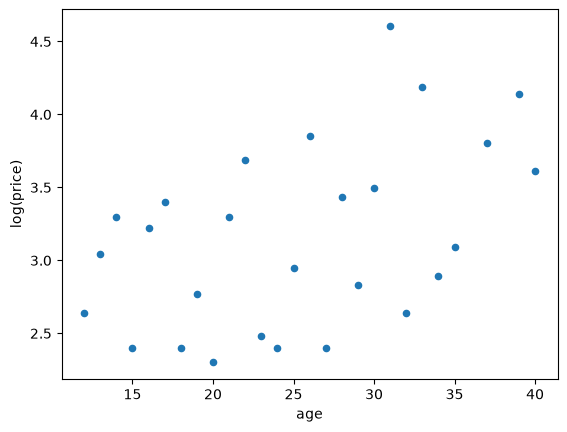

In [11]:
bordeaux_train.plot.scatter(x="age", y="log(price)")

9. Suppose we use a regression decision tree with a single split at 20.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

10. Suppose we use a decision tree with two splits at 20.5 and 30.5. Sketch a plot of what the regression function would look like.

**Sketch on paper and discuss with your partner.**

## Fitting Regression Models with Pipelines: Housing Data (Parts 11–14)

The following solutions predict **SalePrice in dollars**, using exactly the five
requested predictors. I split the 2,930 homes into 60% training, 20% validation,
and 20% test data with `random_state=42`. Every model uses the same split.
Preprocessing is learned from training data inside each pipeline. I compare
settings using validation RMSE; the test set stays unused until the settings
have been chosen. Lower RMSE is better and penalizes large price errors.

### 11. Fit a 10-nearest neighbors regression model

Predict **SalePrice** from **Gr Liv Area**, **Bedroom AbvGr**, **Full Bath**,
**Half Bath**, and **Neighborhood** using a pipeline and column transformers.
Make a scatter plot of predicted price versus actual price.

The four numerical predictors need scaling for distance calculations; otherwise
square footage would dominate the bedroom and bathroom counts. I one-hot encode
Neighborhood and leave its indicators unscaled. An unseen neighborhood is
handled by `handle_unknown="ignore"`.

Training: 1758; validation: 586; test: 586


,RMSE ($),MAE ($),R²
Split,,,
Training,35994.320,22929.873,0.788
Validation,39085.234,26167.386,0.721


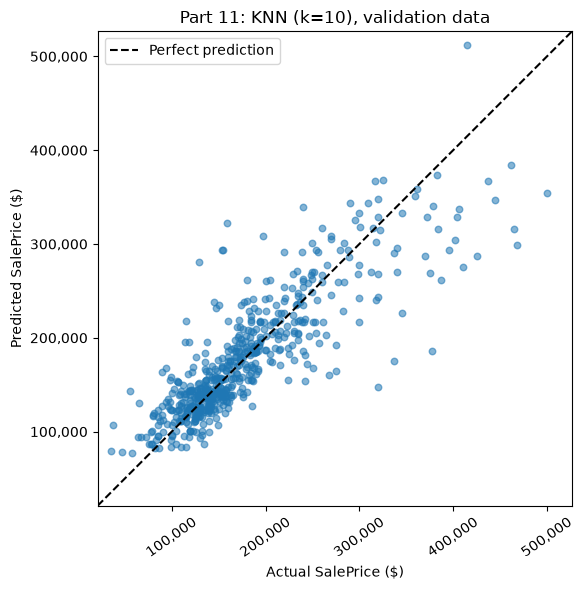

In [12]:
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from matplotlib.ticker import StrMethodFormatter

numeric_features = ["Gr Liv Area", "Bedroom AbvGr", "Full Bath", "Half Bath"]
categorical_features = ["Neighborhood"]
features = numeric_features + categorical_features
X_housing = df_ames[features].copy()
y_housing = df_ames["SalePrice"].copy()
assert not X_housing.isna().any().any()
assert not y_housing.isna().any()

X_development, X_test_housing, y_development, y_test_housing = train_test_split(
    X_housing, y_housing, test_size=0.20, random_state=42
)
X_train_housing, X_val_housing, y_train_housing, y_val_housing = train_test_split(
    X_development, y_development, test_size=0.25, random_state=42
)
print(f"Training: {len(X_train_housing)}; validation: {len(X_val_housing)}; "
      f"test: {len(X_test_housing)}")

def make_knn(k):
    preprocessing = ColumnTransformer([
        ("numeric", StandardScaler(), numeric_features),
        ("neighborhood", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("knn", KNeighborsRegressor(n_neighbors=k)),
    ])

def regression_metrics(model, X, y):
    predictions = model.predict(X)
    return {
        "RMSE ($)": np.sqrt(mean_squared_error(y, predictions)),
        "MAE ($)": mean_absolute_error(y, predictions),
        "R²": r2_score(y, predictions),
    }

def plot_predictions(actual, predicted, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 6))
    ax.scatter(actual, predicted, alpha=0.55, s=22)
    low = min(float(np.min(actual)), float(np.min(predicted)))
    high = max(float(np.max(actual)), float(np.max(predicted)))
    padding = 0.03 * (high - low)
    limits = (low - padding, high + padding)
    ax.plot(limits, limits, "--", color="black", label="Perfect prediction")
    ax.set(xlabel="Actual SalePrice ($)", ylabel="Predicted SalePrice ($)",
           title=title, xlim=limits, ylim=limits)
    ax.xaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
    ax.set_aspect("equal", adjustable="box")
    ax.tick_params(axis="x", rotation=35)
    ax.legend()
    return ax

knn_10 = make_knn(10)
knn_10.fit(X_train_housing, y_train_housing)
knn_10_scores = pd.DataFrame([
    {"Split": "Training", **regression_metrics(knn_10, X_train_housing, y_train_housing)},
    {"Split": "Validation", **regression_metrics(knn_10, X_val_housing, y_val_housing)},
]).set_index("Split")
display(knn_10_scores.round(3))
plot_predictions(y_val_housing, knn_10.predict(X_val_housing),
                 "Part 11: KNN (k=10), validation data")
plt.tight_layout()
plt.show()


Points close to the dashed line have accurate predictions. Points below it are
underpredictions; points above it are overpredictions. KNN averages neighbors'
prices, which tends to pull predictions for unusually expensive homes toward
more typical prices. The validation plot measures predictions for homes that
were not used to fit the model.

### 12. Compare other values of k

I try `k = 1, 3, 5, 10, 15, 25, 50`, changing only the number of neighbors.
The table includes training RMSE to show how training fit differs from
validation performance. I choose the smallest **validation RMSE**, with MAE
reported as a second description of error. I do not use test scores to choose k.

,Training RMSE ($),Validation RMSE ($),Validation MAE ($),Validation R²
k,,,,
1,5839.752,42434.680,29507.889,0.672
3,27127.010,39034.782,25842.386,0.722
5,31700.495,38522.685,25599.728,0.729
10,35994.320,39085.234,26167.386,0.721
15,38045.235,39256.201,26283.327,0.719
25,41120.083,38879.529,26436.183,0.724
50,45142.687,40946.944,27591.344,0.694


Best k among the tested values: 5
Validation RMSE: $38,522.68
Validation MAE: $25,599.73


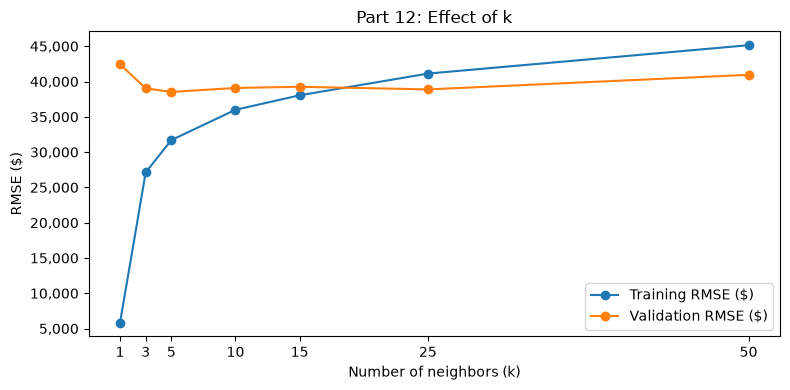

In [13]:
k_values = [1, 3, 5, 10, 15, 25, 50]
knn_models = {}
knn_rows = []
for k in k_values:
    candidate = make_knn(k)
    candidate.fit(X_train_housing, y_train_housing)
    train_scores = regression_metrics(candidate, X_train_housing, y_train_housing)
    val_scores = regression_metrics(candidate, X_val_housing, y_val_housing)
    knn_models[k] = candidate
    knn_rows.append({
        "k": k,
        "Training RMSE ($)": train_scores["RMSE ($)"],
        "Validation RMSE ($)": val_scores["RMSE ($)"],
        "Validation MAE ($)": val_scores["MAE ($)"],
        "Validation R²": val_scores["R²"],
    })

knn_results = pd.DataFrame(knn_rows).set_index("k")
display(knn_results.round(3))
best_k = int(knn_results["Validation RMSE ($)"].idxmin())
print(f"Best k among the tested values: {best_k}")
print(f"Validation RMSE: ${knn_results.loc[best_k, 'Validation RMSE ($)']:,.2f}")
print(f"Validation MAE: ${knn_results.loc[best_k, 'Validation MAE ($)']:,.2f}")

ax = knn_results[["Training RMSE ($)", "Validation RMSE ($)"]].plot(
    marker="o", figsize=(8, 4), title="Part 12: Effect of k"
)
ax.set(xlabel="Number of neighbors (k)", ylabel="RMSE ($)", xticks=k_values)
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()


**Answer:** `k=5` is best among the values tested on this validation split. Its
validation RMSE is **$38,522.68** and its MAE is **$25,599.73**, compared with
RMSE **$39,085.23** for `k=10`. A single neighbor is more sensitive to individual
homes and has a higher validation RMSE (**$42,434.68**). Averaging 50 neighbors
smooths more strongly but also raises validation RMSE (**$40,946.94**).

I choose based on performance for held-out homes, not training error or how
tightly the training scatter hugs the diagonal. The differences between several
intermediate choices are small; another split could produce a different winner.

### 13. Fit and interpret a regression tree with max_depth=4

I use the same five predictors and split. The column transformer one-hot encodes
Neighborhood and passes the numerical predictors through unchanged. A tree
splits on one feature at a time, so its numerical predictors do not need scaling.
Each leaf predicts the mean SalePrice of its training observations.

,RMSE ($),MAE ($),R²
Split,,,
Training,47051.206,32574.671,0.637
Validation,48837.056,33276.558,0.565


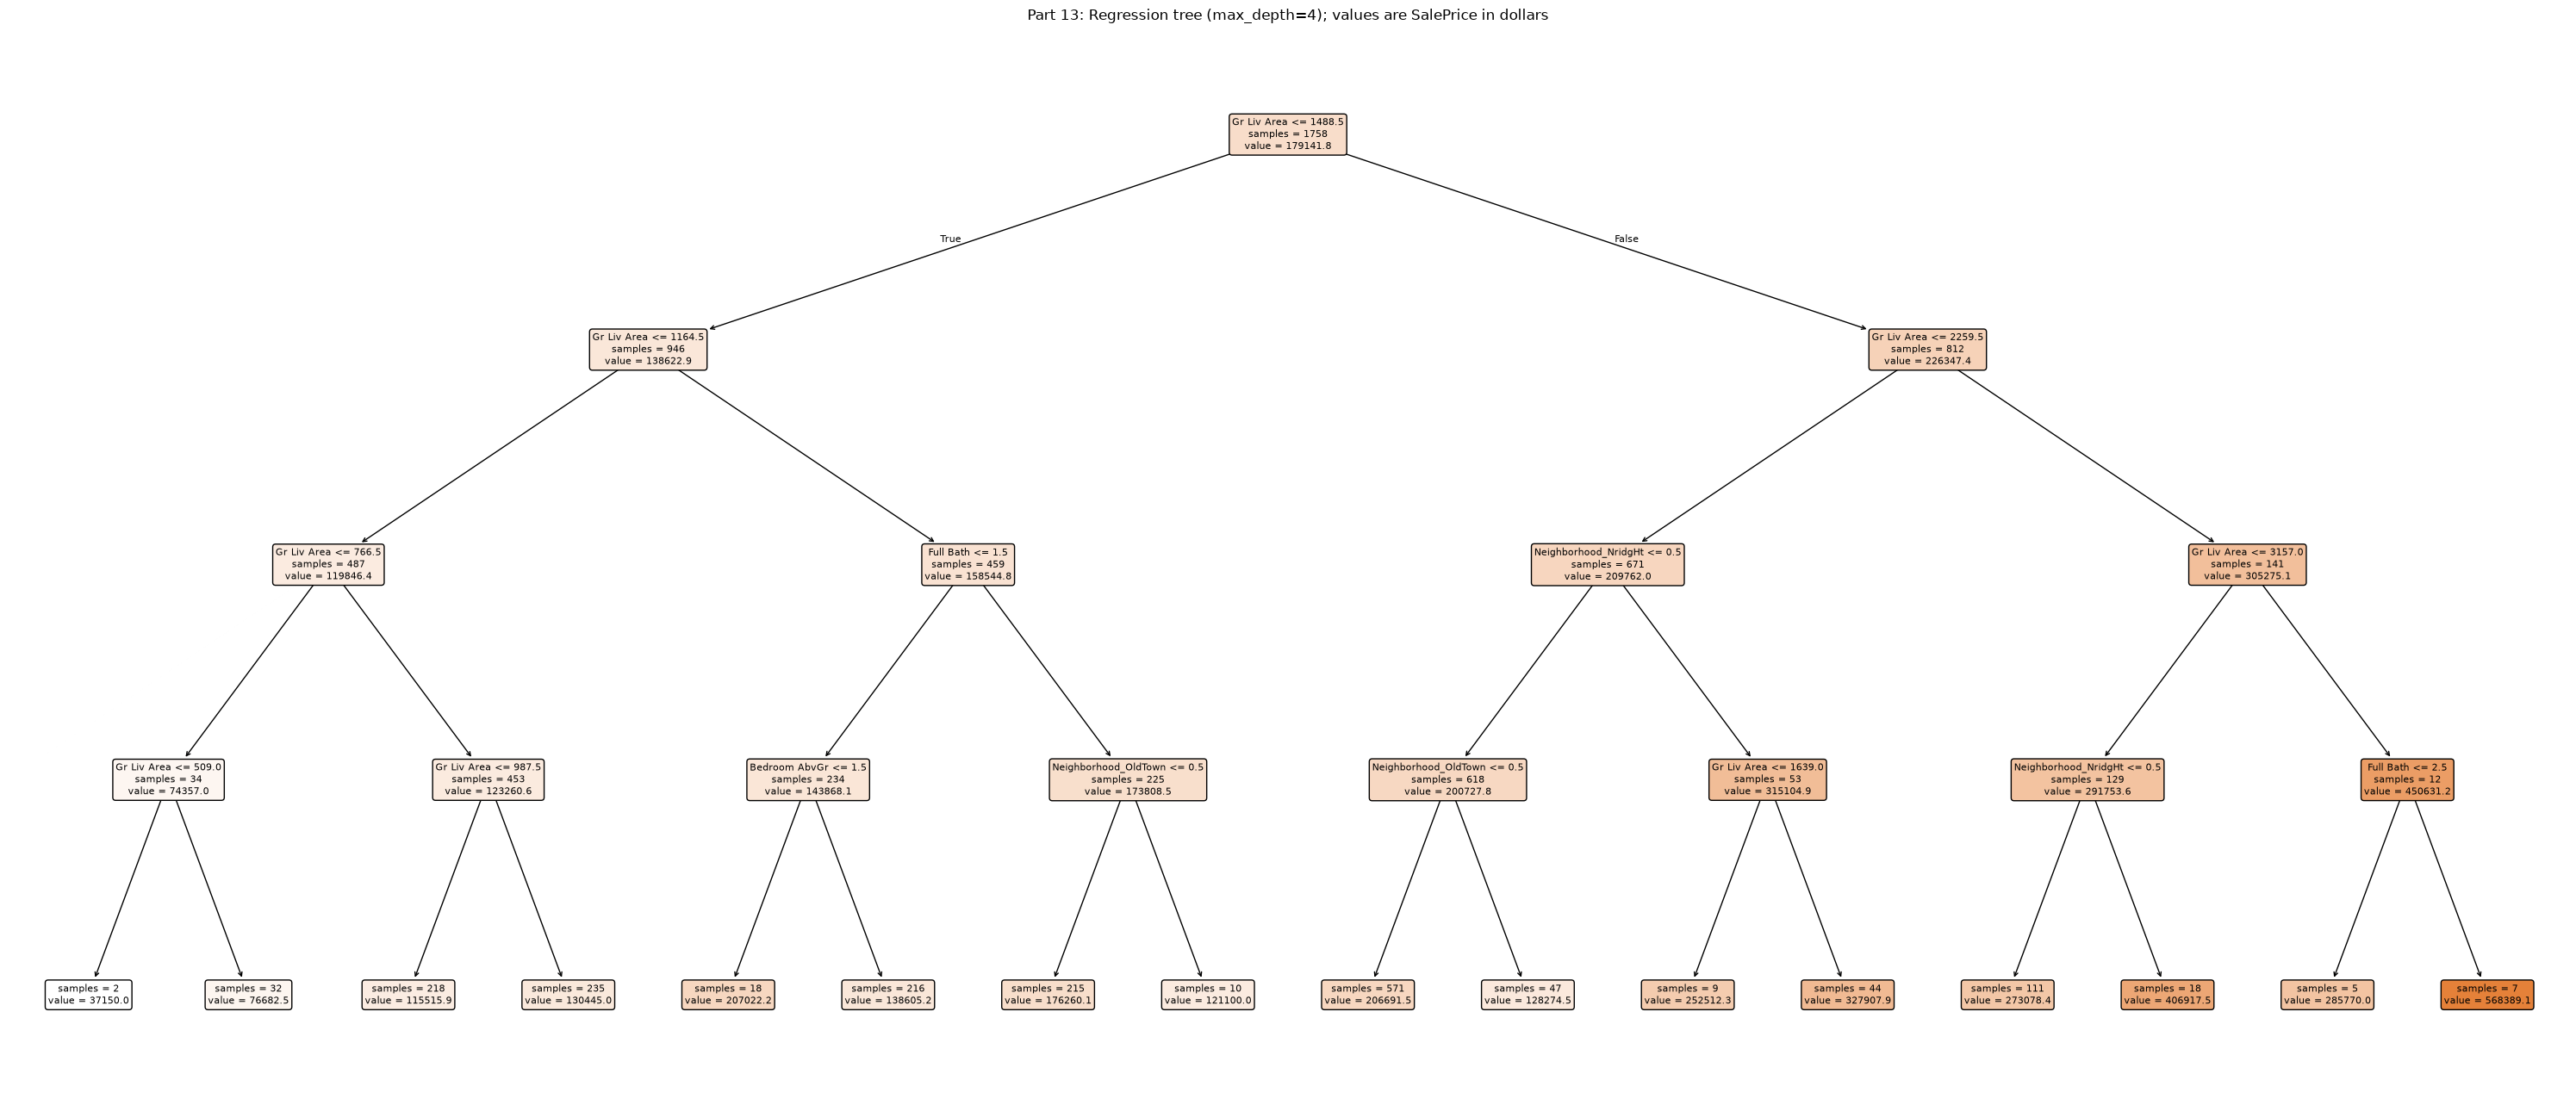

|--- Gr Liv Area <= 1488.5
|   |--- Gr Liv Area <= 1164.5
|   |   |--- Gr Liv Area <= 766.5
|   |   |   |--- Gr Liv Area <= 509.0
|   |   |   |   |--- value: [37150.0]
|   |   |   |--- Gr Liv Area >  509.0
|   |   |   |   |--- value: [76682.5]
|   |   |--- Gr Liv Area >  766.5
|   |   |   |--- Gr Liv Area <= 987.5
|   |   |   |   |--- value: [115515.9]
|   |   |   |--- Gr Liv Area >  987.5
|   |   |   |   |--- value: [130445.0]
|   |--- Gr Liv Area >  1164.5
|   |   |--- Full Bath <= 1.5
|   |   |   |--- Bedroom AbvGr <= 1.5
|   |   |   |   |--- value: [207022.2]
|   |   |   |--- Bedroom AbvGr >  1.5
|   |   |   |   |--- value: [138605.2]
|   |   |--- Full Bath >  1.5
|   |   |   |--- Neighborhood_OldTown <= 0.5
|   |   |   |   |--- value: [176260.1]
|   |   |   |--- Neighborhood_OldTown >  0.5
|   |   |   |   |--- value: [121100.0]
|--- Gr Liv Area >  1488.5
|   |--- Gr Liv Area <= 2259.5
|   |   |--- Neighborhood_NridgHt <= 0.5
|   |   |   |--- Neighborhood_OldTown <= 0.5
|   |   |  

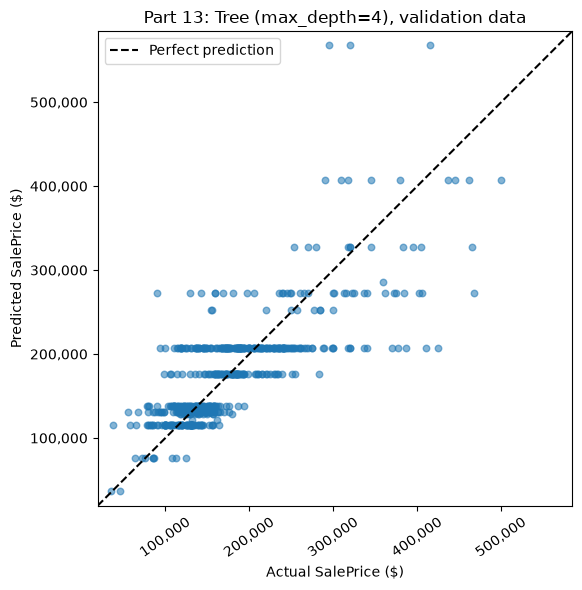

In [14]:
def make_tree(max_depth):
    preprocessing = ColumnTransformer([
        ("numeric", "passthrough", numeric_features),
        ("neighborhood", OneHotEncoder(handle_unknown="ignore", sparse_output=False),
         categorical_features),
    ])
    return Pipeline([
        ("preprocessing", preprocessing),
        ("tree", DecisionTreeRegressor(max_depth=max_depth, random_state=42)),
    ])

tree_4 = make_tree(4)
tree_4.fit(X_train_housing, y_train_housing)
tree_4_scores = pd.DataFrame([
    {"Split": "Training", **regression_metrics(tree_4, X_train_housing, y_train_housing)},
    {"Split": "Validation", **regression_metrics(tree_4, X_val_housing, y_val_housing)},
]).set_index("Split")
display(tree_4_scores.round(3))

tree_feature_names = [
    name.split("__", 1)[-1]
    for name in tree_4.named_steps["preprocessing"].get_feature_names_out()
]
fig, ax = plt.subplots(figsize=(30, 13))
plot_tree(
    tree_4.named_steps["tree"], feature_names=tree_feature_names,
    filled=True, rounded=True, impurity=False, precision=1, fontsize=8, ax=ax,
)
ax.set_title("Part 13: Regression tree (max_depth=4); values are SalePrice in dollars")
plt.tight_layout()
artifact_dir = Path("artifacts")
artifact_dir.mkdir(exist_ok=True)
fig.savefig(artifact_dir / "decision_tree_depth_4.png", dpi=180, bbox_inches="tight")
plt.show()

# A text view makes exact split rules readable alongside the full tree graphic.
print(export_text(tree_4.named_steps["tree"],
                  feature_names=list(tree_feature_names), decimals=1))

plot_predictions(y_val_housing, tree_4.predict(X_val_housing),
                 "Part 13: Tree (max_depth=4), validation data")
plt.tight_layout()
plt.show()


**Interpretation:** The first split is **Gr Liv Area ≤ 1,488.5 square feet**.
The next area thresholds are 1,164.5 on the smaller-home branch and 2,259.5 on
the larger-home branch. Living area is therefore central to this fitted tree.
Later splits also use full bathrooms, bedrooms, and indicators for NridgHt and
OldTown. Half Bath was available but was not selected in this depth-4 tree.

For example, follow the branch with **1,488.5 < Gr Liv Area ≤ 2,259.5**. For
homes in **NridgHt**, an additional split at 1,639 square feet gives leaf
predictions of about **$252,512** and **$327,908**. For homes outside NridgHt,
the tree predicts about **$128,274** in OldTown and **$206,692** outside OldTown.
A one-hot indicator ≤ 0.5 means the home is outside that neighborhood; > 0.5
means it is in that neighborhood. Each number is a training-group mean,
not an estimated causal effect of a neighborhood or home feature.

The depth-4 tree has validation RMSE **$48,837.06** and MAE **$33,276.56**.
The horizontal bands in its scatter plot reflect the finite set of leaf
predictions: every home ending in the same leaf receives the same price.

### 14. Compare other maximum tree depths

I compare `max_depth = 2, 3, 4, 5, 6, 8, 10, None`. `None` allows an unrestricted
tree. All other choices stay fixed. I choose depth by the smallest validation
RMSE and compare training error to validation error to look for overfitting.

,Leaves,Training RMSE ($),Validation RMSE ($),Validation MAE ($),Validation R²
max_depth,,,,,
2,4,58132.547,54463.007,39259.194,0.459
3,8,52507.098,50961.506,35590.430,0.527
4,16,47051.206,48837.056,33276.558,0.565
5,32,42355.460,45753.066,31716.261,0.618
6,59,38087.866,44238.077,30634.977,0.643
8,161,30484.962,41698.121,28266.625,0.683
10,322,24919.929,41080.867,26711.452,0.692
None,1578,4248.698,43709.077,28913.527,0.652


Best max_depth among the tested values: 10
Validation RMSE: $41,080.87
Validation MAE: $26,711.45


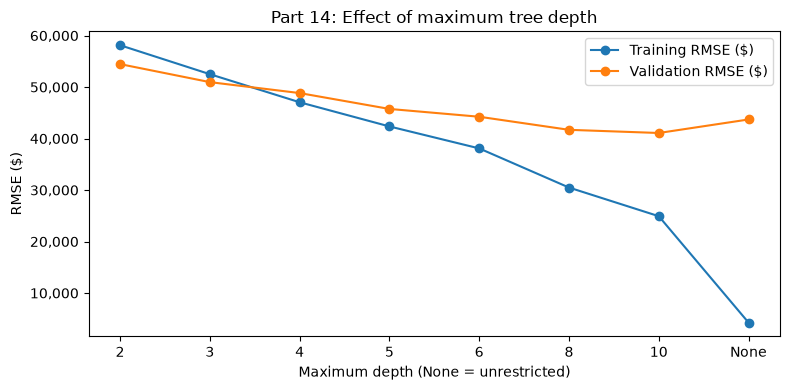

In [15]:
depth_values = [2, 3, 4, 5, 6, 8, 10, None]
tree_models = {}
tree_rows = []
for depth in depth_values:
    candidate = make_tree(depth)
    candidate.fit(X_train_housing, y_train_housing)
    train_scores = regression_metrics(candidate, X_train_housing, y_train_housing)
    val_scores = regression_metrics(candidate, X_val_housing, y_val_housing)
    label = "None" if depth is None else str(depth)
    tree_models[label] = candidate
    tree_rows.append({
        "max_depth": label,
        "Leaves": candidate.named_steps["tree"].get_n_leaves(),
        "Training RMSE ($)": train_scores["RMSE ($)"],
        "Validation RMSE ($)": val_scores["RMSE ($)"],
        "Validation MAE ($)": val_scores["MAE ($)"],
        "Validation R²": val_scores["R²"],
    })

tree_results = pd.DataFrame(tree_rows).set_index("max_depth")
display(tree_results.round(3))
best_depth_label = tree_results["Validation RMSE ($)"].idxmin()
print(f"Best max_depth among the tested values: {best_depth_label}")
print(f"Validation RMSE: ${tree_results.loc[best_depth_label, 'Validation RMSE ($)']:,.2f}")
print(f"Validation MAE: ${tree_results.loc[best_depth_label, 'Validation MAE ($)']:,.2f}")

ax = tree_results[["Training RMSE ($)", "Validation RMSE ($)"]].plot(
    marker="o", figsize=(8, 4), title="Part 14: Effect of maximum tree depth"
)
ax.set(xlabel="Maximum depth (None = unrestricted)", ylabel="RMSE ($)")
ax.yaxis.set_major_formatter(StrMethodFormatter("{x:,.0f}"))
plt.tight_layout()
plt.show()


**Answer:** `max_depth=10` is best among the tested depths on this validation
split, with validation RMSE **$41,080.87** and MAE **$26,711.45**. It improves
on depth 4 (RMSE **$48,837.06**) and depth 8 (RMSE **$41,698.12**).

The shallow trees underfit: their few leaves cannot capture enough differences
between homes. As depth grows, training RMSE decreases. However, the unrestricted
tree has a higher validation RMSE (**$43,709.08**) than depth 10 despite fitting
training data more closely. That pattern is evidence of overfitting. I choose
depth 10 using validation RMSE, not the smallest training error. This is the
best of the settings tested on one split, not proof of a universally optimal depth.

### Final evaluation on the reserved test set

With k and depth fixed using validation scores, I refit each selected pipeline
on all development data (training + validation, 80% of the homes). I then
evaluate each once on the reserved 20% test set. These scores estimate prediction
error on new homes; I do not use them to change the settings.

,RMSE ($),MAE ($),R²
Model,,,
KNN (k=5),42435.129,26402.876,0.775
Tree (max_depth=10),47136.269,29838.013,0.723


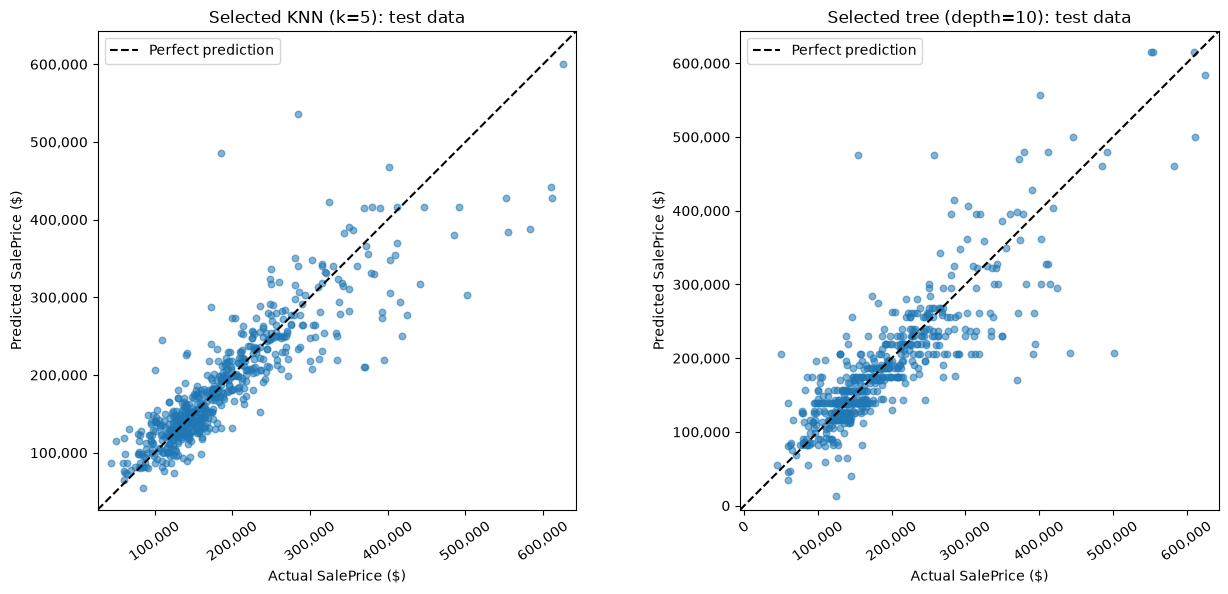

In [16]:
final_knn = clone(knn_models[best_k]).fit(X_development, y_development)
final_tree = clone(tree_models[best_depth_label]).fit(X_development, y_development)
test_results = pd.DataFrame([
    {"Model": f"KNN (k={best_k})",
     **regression_metrics(final_knn, X_test_housing, y_test_housing)},
    {"Model": f"Tree (max_depth={best_depth_label})",
     **regression_metrics(final_tree, X_test_housing, y_test_housing)},
]).set_index("Model")
display(test_results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
plot_predictions(y_test_housing, final_knn.predict(X_test_housing),
                 f"Selected KNN (k={best_k}): test data", ax=axes[0])
plot_predictions(y_test_housing, final_tree.predict(X_test_housing),
                 f"Selected tree (depth={best_depth_label}): test data", ax=axes[1])
plt.tight_layout()
plt.show()


RMSE and MAE above are both in dollars. RMSE is more sensitive to large errors,
so a gap between RMSE and MAE indicates that some homes have much larger errors
than typical homes. The diagonal in each plot represents perfect prediction.
The test results describe these two fixed, refitted models on this reserved
sample; they are not another tuning step.

On the reserved test set, the refitted **KNN (k=5)** has RMSE **$42,435.13** and MAE **$26,402.88**; the refitted **tree (depth=10)** has RMSE **$47,136.27** and MAE **$29,838.01**. KNN has lower errors on this test sample, consistent with its lower validation error.